In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import os

from eazy import photoz
from eazy import hdf5 as eazyh5

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

In [61]:


def get_n_colors(n, cmap_name="viridis"):
    cmap = plt.get_cmap(cmap_name)  # Get colormap
    return [cmap(i / (n - 1)) for i in range(n)]  # Sample n colors

def MidFactor(n):
    # Create a list to store divisors
    divisors = []
    # Iterate from 1 to n and check divisibility
    for i in range(1, n + 1):
        if n % i == 0:
            # If 'i' divides 'n' evenly, it's a divisor
            divisors.append(i)
            
    return divisors[len(divisors)//2]
            
from matplotlib.ticker import ScalarFormatter
import matplotlib.patheffects as path_effects
from matplotlib.colors import to_rgba

plt.rcParams['font.size']= 24
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20
plt.rcParams['ytick.direction'] = "in"
plt.rcParams['xtick.direction'] = "in"

plt.rcParams["xtick.major.size"] = 7
plt.rcParams["ytick.major.size"] = 7

plt.rcParams["xtick.minor.size"] = plt.rcParams["xtick.major.size"]/2.0
plt.rcParams["ytick.minor.size"] = plt.rcParams["ytick.major.size"]/2.0

plt.rcParams['xtick.minor.visible'] = False
plt.rcParams['ytick.minor.visible'] = False

plt.rcParams['xtick.major.pad'] = 7

plt.rcParams['axes.linewidth'] = 2.0
plt.rcParams['font.family'] = 'serif'
plt.rcParams["text.usetex"] = True

from matplotlib.ticker import LogLocator

## l-l-l-lava ch-ch-ch-chicken, 
## steve's lava chicken yeah it's tasty as hell, 
## ooh mamacita now you're ringin' a bell, 
## crispy and juicy now you're havin' a snack, 
## ooh super spicy it's a lava attack!


In [10]:
h5file = '/Users/jordan/Documents/Epochs/eazy/smiles_zphot.out.h5'

In [11]:
new = eazyh5.initialize_from_hdf5(h5file=h5file)

set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR y
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/eazy/smiles_phot_eazy.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTERS_RES FILTER.RES.latest
set param: FILTER_FORMAT 1.0
set param: FITTER nnls
set param: FIX_ZSPEC n
set param: GET_ZP_OFFSETS n
set param: H0 70.0
set param: HESS_THRESHOLD 1.0
set param: IGM_SCALE_TAU 1.0
set param: MAGNITUDES n
set param: MAIN_OUTPUT_FILE /Users/jordan/Documents/Epochs/eazy/smiles_zphot.out
set param: MW_EBV 0.0
set param: NMF_TOLERANCE 0.0001
set param: NOT_OBS_THRESHOLD -90
set param: N_MIN_COLORS 3
set param: OBS_SED_FILE n
set param: OMEGA_L 0.7
set param: OMEGA_M 0.3
set param: OUTPUT_DIRECTORY /Users/jordan/Documents/Epochs/eazy/
set param: POFZ_FILE n
set param: PRINT_E

371it [00:00, 1271.07it/s]


h5: read tweak_fsps_QSF_12_v3_001.dat
h5: read tweak_fsps_QSF_12_v3_002.dat
h5: read tweak_fsps_QSF_12_v3_003.dat
h5: read tweak_fsps_QSF_12_v3_004.dat
h5: read tweak_fsps_QSF_12_v3_005.dat
h5: read tweak_fsps_QSF_12_v3_006.dat
h5: read tweak_fsps_QSF_12_v3_007.dat
h5: read tweak_fsps_QSF_12_v3_008.dat
h5: read tweak_fsps_QSF_12_v3_009.dat
h5: read tweak_fsps_QSF_12_v3_010.dat
h5: read tweak_fsps_QSF_12_v3_011.dat
h5: read tweak_fsps_QSF_12_v3_012.dat
h5: read binc100z001age6_cloudy.dat
h5: read binc100z001age65_cloudy.dat
h5: read binc100z001age7_cloudy.dat
h5: read binc100z001age6.dat
h5: read binc100z001age65.dat
h5: read binc100z001age7.dat
fit_best: 0.2 s (n_proc=1,  NOBJ=5072)


In [ ]:
smiles_percentiles = new.pz_percentiles((0.5, 0.16, 0.84))

smiles_z50 = smiles_percentiles[:,0]
smiles_z16 = smiles_percentiles[:,1]
smiles_z84 = smiles_percentiles[:,2]

smiles_zlo = smiles_z50 - smiles_z16
smiles_zhi = smiles_z84 - smiles_z50

smiles_zbest = new.zml


True


In [17]:
## Load in the smiles nirspec catalogue
with fits.open("/Users/jordan/Documents/Epochs/data/hlsp_smiles_jwst_nirspec_goodss_multi_v1.0_catalog.fits") as hdul:
    smiles_nirspec = hdul[1].data
    cols = hdul[1].columns
    print(cols)

ColDefs(
    name = 'NIRCAM_ID'; format = 'K'
    name = 'MIRI_ID'; format = 'K'
    name = 'RA'; format = 'D'
    name = 'DEC'; format = 'D'
    name = 'Z_PHOTO'; format = 'D'
    name = 'Z_SPEC'; format = 'D'
    name = 'Q'; format = '1A'
    name = 'AGN'; format = 'K'
    name = 'EXTENDED'; format = 'K'
    name = 'KEYWORDS'; format = '58A'
)


In [72]:
catalogue = SkyCoord(ra=new.cat['ra']*u.degree, dec=new.cat['dec']*u.degree)
c = SkyCoord(ra=smiles_nirspec.field('ra')*u.degree, dec=smiles_nirspec.field('dec')*u.degree)
idx, d2d, d3d = c.match_to_catalog_sky(catalogue)

sep_constraint = d2d < 0.3*u.arcsec

idx_catalogue = idx[sep_constraint]
idx_smiles = np.where(sep_constraint)[0]

smiles_zspec = smiles_nirspec.field('z_spec')

In [ ]:
zspec=smiles_zspec[idx_smiles]
zphot=smiles_zbest[idx_catalogue]

zphot >= 1 

array([False,  True,  True,  True, False,  True,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False,  True,  True,  True,
        True, False, False, False,  True, False,  True, False, False,
       False, False,  True, False,  True, False, False, False,  True,
        True, False,  True,  True,  True, False,  True, False,  True,
        True, False,  True,  True,  True, False, False, False,  True,
        True,  True,  True,  True,  True, False,  True,  True, False,
       False, False,  True, False,  True,  True, False, False,  True,
        True,  True,  True, False, False,  True,  True,  True, False,
        True,  True,  True, False,  True,  True, False,  True, False,
       False,  True,  True,  True, False, False, False, False,  True,
        True,  True, False, False, False,  True,  True, False,  True,
       False,  True, False, False, False,  True])

In [153]:
def compute_sigmaNMAD(zspec, zphot):
    deltaz = zphot - zspec
    sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )
    return sigmaNMAD

def compute_outliers(zspec, zphot):
    thresh = 0.15

    outlier_upidx = (1+zphot) >= (1+zspec)*(1+thresh)
    outlier_downidx = (1+zphot) <= (1+zspec)*(1-thresh)


    outlier_frac = (sum(outlier_upidx) + sum(outlier_downidx))/len(zspec)
    
    return outlier_frac


sigmaNMAD = compute_sigmaNMAD(zspec=smiles_zspec[idx_smiles], zphot=smiles_zbest[idx_catalogue])
outlier_frac = compute_outliers(zspec=smiles_zspec[idx_smiles], zphot=smiles_zbest[idx_catalogue])
outlier_frac_z4 = compute_outliers(zspec=smiles_zspec[idx_smiles][smiles_zspec[idx_smiles]>4], zphot=smiles_zbest[idx_catalogue][smiles_zspec[idx_smiles]>4])

/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_7276/3453433819.py:3: RuntimeWarning: divide by zero encountered in divide
  sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )


In [154]:
outlier_frac_z4

np.float64(0.42857142857142855)

In [ ]:
zspec ## coonfirm that it is the same as celestial

array([ 1.1204,  1.9068,  1.6862,  7.2432, -1.    ,  1.2208,  2.1642,
        2.7404,  2.4808,  1.6736,  2.5892,  1.0984,  2.4541,  1.3171,
        2.3941,  1.9982,  2.5834,  2.6937,  2.4715,  2.0694,  2.6992,
        1.0414,  1.0938,  1.0969,  2.6995,  1.4477,  2.2282,  3.9687,
        2.3165,  0.8951,  1.0969,  2.318 ,  0.4251,  3.605 ,  1.298 ,
        1.2991,  3.6067,  1.0366,  1.0185,  0.7339,  2.4006,  1.2204,
        2.6198,  3.9182,  1.6107,  2.1981,  3.0833,  2.4862,  2.5831,
        1.5695,  1.613 ,  2.128 ,  2.5854,  4.4986,  1.1125,  2.5762,
        2.3174,  1.8873,  2.0085,  0.7723,  1.1727,  2.6307,  2.345 ,
        2.6151,  2.6311,  2.084 ,  1.4909,  3.0196,  0.3379,  2.6413,
        1.6117,  1.0955,  1.4391,  0.9547,  1.3167,  5.4696,  1.9981,
        1.9901,  1.0379,  3.3319,  2.4541,  1.3078,  1.9061,  2.2251,
        1.2887, -1.    ,  2.0755,  2.2356,  2.613 ,  1.0967,  2.0107,
        2.8775,  2.0376,  1.3937,  1.609 ,  5.3887,  1.3891,  1.3833,
        2.6767,  1.2

Text(0.5, 0, 'zPhot - zSpec')

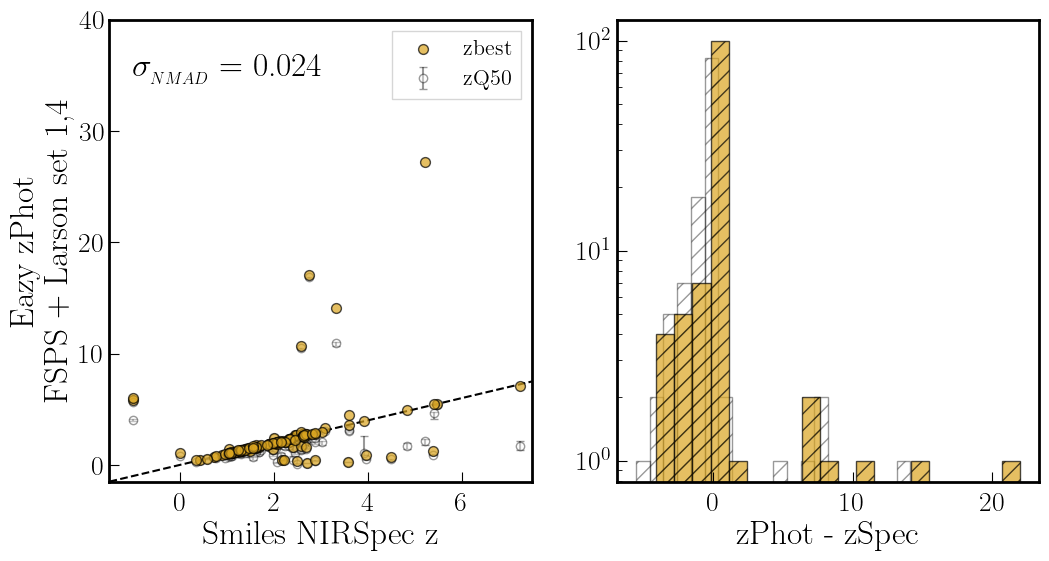

In [175]:
fig, ax = plt.subplots(1, 2, figsize = (12,6))
# ax.scatter(
#     new.zbest[idx_catalogue],
#     smiles_nirspec.field('Z_SPEC')[idx_smiles]
# )
# plt.xlim([0,10]),
# plt.ylim([0,10])

ax[0].errorbar(
    smiles_zspec[idx_smiles],
    smiles_z50[idx_catalogue], 
    yerr = [smiles_zlo[idx_catalogue], smiles_zhi[idx_catalogue]],
    fmt = "o",
    ls = "",
    markeredgecolor = "black",
    markerfacecolor = "white",
    ecolor = "black",
    alpha = 0.4,
    capsize = 3, 
    markersize = 6, 
    label = "zQ50"
)
ax[0].scatter(
    smiles_zspec[idx_smiles],
    smiles_zbest[idx_catalogue], 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    alpha = 0.7,
    label = "zbest"
)
ax[0].text(
    -1, 35, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {sigmaNMAD:.3f}"
)
ax[0].set_xlim([-1.5, 7.5]),
ax[0].set_ylim([-1.5, 40])
ax[0].axline((0, 0), slope=1, 
             color='black', linestyle='--'
)
# ax[0].plot(np.linspace(-400, 400, 40) + 1, 1.15 * (np.linspace(-400, 400, 40) + 1), 
#            color='black', linestyle=':'
# )
# ax[0].plot(np.linspace(-400, 400, 40) + 1, 0.85 * (np.linspace(-400, 400, 40) + 1), 
#            color='black', linestyle=':'
# )
ax[0].legend(fontsize = 16, fancybox = False)
ax[0].set_xlabel('Smiles NIRSpec z')
ax[0].set_ylabel('Eazy zPhot \n FSPS + Larson set 1,4')

ax[1].hist(
    smiles_z50[idx_catalogue] - smiles_zspec[idx_smiles], bins = 20,
    edgecolor = "black", facecolor = "none", hatch = "//", alpha = 0.4,
    
)
ax[1].hist(
    smiles_zbest[idx_catalogue] - smiles_zspec[idx_smiles], bins = 20,
    edgecolor = "black", facecolor = "goldenrod", hatch = "//", alpha = 0.7,
)
ax[1].set_yscale('log')
ax[1].set_xlabel("zPhot - zSpec")

(<Figure size 800x400 with 2 Axes>,
 OrderedDict([('ix', np.int64(4439)),
              ('id', np.int64(4440)),
              ('z', np.float32(39.62201)),
              ('z_spec', np.float32(-1.0)),
              ('pivot',
               array([  4318.82810211,   5920.81887956,   7043.22201191,   7692.30432928,
                        8056.87950929,   9022.92219271,   9032.68320402,  11543.00930164,
                       15007.45492632,  16272.4583707 ,  18452.20651021,  19886.47814337,
                       20955.30780847,  25036.69684796,  27623.47466385,  29894.8160696 ,
                       33623.02517333,  35682.2778744 ,  40820.73020365,  42812.86944883,
                       44037.1390651 ,  46302.41760368,  48155.79518006,  56326.12445204,
                       76364.11731878,  99471.09258361, 128093.58773603, 150481.55266467,
                      179696.73556279, 208013.89910584, 252296.63747354])),
              ('model',
               array([0.00000000e+00, 0.0000000

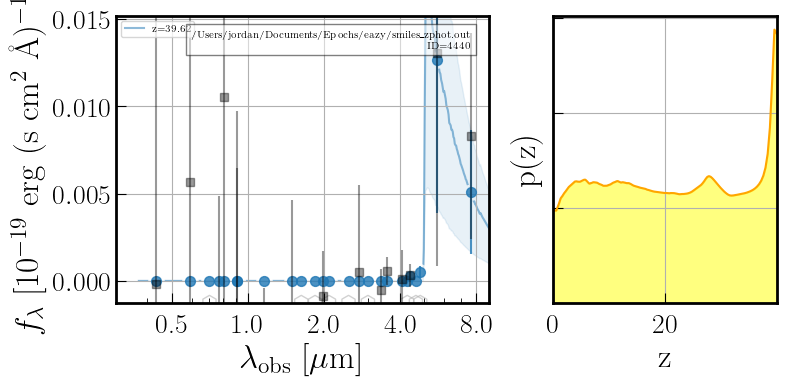

In [66]:
foo = new.show_fit(id = 4440)

foo